# Hands-on P02: Teori Neural Network *(Visual-First · Mikro-Task)*

**Durasi Hands-on:** ±55 menit (Tahap 0 → Tahap 5.4, selaras **Bab 3 Slide 20–33** & **Slide 43–49**)  
**Dataset Proyek Utama:** **Disney Frozen Figurine (`data/frozen_v1/`)** — 5 kelas (`anna, elsa, kristoff, olaf, sven`), dibaca secara **dinamis** dari `DATA_DIR` dan `metadata.csv`.  
**Gaya Kode:** Super ramah pemula — kode grafik sudah dirapikan ke **Alat Visualisasi Siap Pakai** sehingga setiap sel kerja Anda cuma **3–7 baris** dan langsung memunculkan **output gambar nyata**!

### Peta Perjalanan 1 Foto Elsa (100% Cerminan Bab 3):
- **Tahap 0 (Persiapan):** Setup 3 tahap, muat alat visualisasi, & intip galeri 5 karakter Frozen *(0 coding, tinggal `Shift+Enter`)*.
- **Tahap 1 (Slide 20 & 44 — Piksel → Angka):**
  - `1.1` Ubah foto Elsa ke grid mini `8×8` & normalisasi `/ 255.0` (`# TODO 1`)
  - `1.2` Ambil 1 piksel di gaun biru Elsa `[4, 2]` & lihat nilai **R, G, B** (`# TODO 2`)
- **Tahap 2 (Slide 21–24 & 45 — Flatten, Dense & Parameter):**
  - `2.1` Luruskan foto `8×8` jadi **pita 1D piksel berwarna** (`P1 x1–3 .. P64 x190–192`) dengan `.flatten()` (`# TODO 3`)
  - `2.2` Hitung skala neuron `224×224×3` (`150.528`) & total kabel `Dense` `W + b` (`752.645`) (`# TODO 4`)
- **Tahap 3 (Slide 27–29 & 46 — Weight, Bias, Aktivasi, Softmax & Loss):**
  - `3.1` Hitung 1 neuron pakai rumus kali-tambah biasa `r*w_r + g*w_g + b*w_b + bias` & bandingkan **Gaun Biru vs Dinding** (`# TODO 5`)
  - `3.2` Pangkas angka minus jadi `0` dengan `ReLU` (`# TODO 6`)
  - `3.3` Mainkan angka skor mentah & lihat **5 foto Frozen + bar `Softmax 100%` + `Loss (−ln P)`**!
- **Tahap 4 (Slide 24, 31 & 47 — Bangun Model 1-Layer `Dense` & Tes "Model Bayi"):**
  - `4.1` Muat seluruh foto Frozen `64×64`
  - `4.2` Susun 2 layer Keras (`Flatten` + `Dense(5, softmax)`) & cek `61.445` parameter (`# TODO 7`)
  - `4.3` **Uji tebakan "Model Bayi" (Epoch 0 — *Weight Initialization* acak!)**
- **Tahap 5 (Slide 30–33 & 48–49 — Training, Adam, Batch Size, Overfitting & Intip Bobot):**
  - `5.1` Latih model `30` Epoch (`model.fit`, `Batch=16 → 9 Step/Epoch`) (`# TODO 8`)
  - `5.2` Plot kurva **Loss turun** (`< 1.0`) & **Akurasi naik**
  - `5.3` **Bandingkan Tebakan Before (Epoch 0) vs After (Epoch 30)** + **Tes Visual 5 Foto Ramai (`X_5ramai`)** & cek **Polos vs Ramai (*Shortcut Learning*)**!
  - `5.4` *(Bonus Aha!)* **Intip Peta Fokus Bobot `ΔW`** yang dipelajari tiap karakter + eksperimen ubah 1 angka *Learning Rate*!

> **Cara Menjalankan:** Tekan `Shift + Enter` berurutan dari atas ke bawah. Pada versi peserta, lengkapi hanya bagian bertanda `# TODO` (1–2 baris per tugas!).

## Setup 1/3: Memanggil Pustaka (*Libraries*) Python
Kita panggil alat-alat Python yang diperlukan dan mencetak versinya agar eksperimen dapat direproduksi (*reproducible*).

In [1]:
import os                           # Untuk membaca pengaturan komputer / environment
import random                       # Untuk mengunci angka acak bawaan Python
from pathlib import Path            # Untuk mengatur alamat folder & file

import numpy as np                  # NumPy: untuk mengolah matriks/tabel angka
import pandas as pd                 # Pandas: untuk membuat tabel laporan
import matplotlib.pyplot as plt     # Matplotlib: untuk menampilkan gambar & grafik
import tensorflow as tf             # TensorFlow/Keras: untuk membangun & melatih Neural Network
from PIL import Image, ImageOps      # Pillow: membuka, koreksi EXIF & resize foto Frozen

print("✅ Semua library berhasil dimuat!")
print("Versi NumPy      :", np.__version__)
print("Versi TensorFlow :", tf.__version__)

✅ Semua library berhasil dimuat!
Versi NumPy      : 2.5.5
Versi TensorFlow : 2.21.0


## Setup 2/3: Deteksi Google Colab & Mengunci `SEED = 42`
Notebook ini bisa berjalan di **Google Colab** maupun di **komputer lokal**. Kita kunci `SEED = 42` agar hasil acak selalu konsisten setiap kali dijalankan ulang.

In [2]:
# Cek apakah notebook dijalankan di Google Colab atau lokal
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Kunci angka acak (SEED = 42) untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Berjalan di Google Colab :", IN_COLAB)
print("SEED dikunci pada        :", SEED)

Berjalan di Google Colab : False
SEED dikunci pada        : 42


## Setup 3/3: Konfigurasi Proyek & Alamat Folder
Daftar kelas, ukuran gambar (`IMG_SIZE = 224`), dan folder data disimpan sebagai variabel konfigurasi di sini (tidak di-*hardcode*) agar nanti mudah diganti ke foto Disney buatan sendiri.

In [3]:
# Konfigurasi utama proyek (dinamis — tetap aman jika jumlah foto dataset ditambah nanti)
IMG_SIZE = 224
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"
CLASS_NAMES = ["anna", "elsa", "kristoff", "olaf", "sven"]


# Cari folder utama proyek yang memiliki folder "data/"
BASE_DIR = Path(".")
for folder in [Path("."), Path(".."), Path("../.."), Path("../../..")]:
    if (folder / "data").exists():
        BASE_DIR = folder
        break

# Gunakan dataset proyek utama Disney Frozen (otomatis fallback ke data/sample jika belum tersedia)
DATA_DIR = BASE_DIR / "data" / "frozen_v1"
if not DATA_DIR.exists():
    DATA_DIR = BASE_DIR / "data" / "sample"
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Mode SMOKE_TEST  :", SMOKE_TEST)
print("Folder Dataset   :", DATA_DIR.resolve())
print("Folder Hasil     :", RESULTS_DIR.resolve())

Mode SMOKE_TEST  : False
Folder Dataset   : D:\Haerul\HaloTech-Private-DeepLearning\data\frozen_v1
Folder Hasil     : D:\Haerul\HaloTech-Private-DeepLearning\results


---
## Tahap 0.2: Muat Alat Visualisasi Siap Pakai *(Cukup Tekan `Shift + Enter`)*

Agar sel latihan di bawah tetap super singkat (3–7 baris), seluruh kode menggambar grafik `matplotlib` kita kumpulkan rapi di satu sel ini. **Anda tidak perlu mengubah isi sel ini** — cukup jalankan sekali!

In [4]:
# ==============================================================================
# ALAT VISUALISASI SIAP PAKAI (Tinggal Shift+Enter — TIDAK PERLU DIUBAH!)
# Fungsi ini memisahkan kode grafik Matplotlib agar sel tugas Anda tetap 3-6 baris.
# ==============================================================================
import matplotlib.patches as patches

def _buka_foto_aman(path_foto):
    """Buka foto RGB dengan koreksi orientasi EXIF (melanjutkan kebiasaan baik P01)."""
    return ImageOps.exif_transpose(Image.open(path_foto)).convert("RGB")

def _crop_figur(im, frac=0.68):
    w, h = im.size
    side = int(min(w, h) * frac)
    cx, cy = w // 2, int(h * 0.48)
    left = max(0, min(w - side, cx - side // 2))
    top = max(0, min(h - side, cy - side // 2))
    return im.crop((left, top, left + side, top + side))

def tampilkan_galeri_frozen(df_meta, data_dir):
    fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(12, 2.7))
    for i, kls in enumerate(CLASS_NAMES):
        baris = df_meta[(df_meta["kelas"] == kls) & (df_meta["kondisi"] == "polos")].iloc[0]
        foto = _crop_figur(_buka_foto_aman(data_dir / baris["file"]))
        axes[i].imshow(foto)
        axes[i].set_title(kls.capitalize(), fontweight="bold")
        axes[i].axis("off")
    plt.suptitle("5 Karakter Proyek Frozen (Image Classification)", fontweight="bold")
    plt.tight_layout()
    plt.show()

def tampilkan_piksel_grid(foto_asli, foto_mini, pr=4, pc=2):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.4, 4.1))
    ax1.imshow(foto_asli)
    step = foto_asli.size[0] / foto_mini.shape[0]
    ax1.add_patch(patches.Rectangle((pc * step, pr * step), step, step, lw=2.8, edgecolor="#EA4335", facecolor="none"))
    ax1.set_title(f"Foto Asli Elsa (kotak merah = [{pr}, {pc}] gaun)", fontweight="bold")
    ax1.axis("off")
    ax2.imshow(foto_mini, interpolation="nearest")
    for r in range(foto_mini.shape[0]):
        for c in range(foto_mini.shape[1]):
            lum = 0.299 * foto_mini[r, c, 0] + 0.587 * foto_mini[r, c, 1] + 0.114 * foto_mini[r, c, 2]
            ax2.text(c, r, f"{lum:.1f}", ha="center", va="center", fontsize=8, fontweight="bold",
                     color="#FFFFFF" if lum < 0.54 else "#202124")
    ax2.add_patch(patches.Rectangle((pc - 0.5, pr - 0.5), 1, 1, lw=2.8, edgecolor="#EA4335", facecolor="none"))
    ax2.set_xticks(range(foto_mini.shape[1])); ax2.set_yticks(range(foto_mini.shape[0]))
    ax2.set_title("Grid 8×8 (Angka = kecerahan · tiap kotak punya 3 nilai R, G, B)", fontweight="bold", color="#1A73E8", fontsize=10.5)
    plt.tight_layout()
    plt.show()

def tampilkan_zoom_piksel(foto_mini, pr, pc, rgb):
    r_v, g_v, b_v = float(rgb[0]), float(rgb[1]), float(rgb[2])
    dom = ["Merah (R)", "Hijau (G)", "Biru (B)"][int(np.argmax([r_v, g_v, b_v]))]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.4, 3.2), gridspec_kw={"width_ratios": [1, 1.85]})
    ax1.imshow(np.ones((10, 10, 3)) * np.array([r_v, g_v, b_v]))
    ax1.set_title(f"Warna Asli Piksel [{pr}, {pc}]\nRGB = [{r_v:.2f}, {g_v:.2f}, {b_v:.2f}]", fontweight="bold", fontsize=10)
    ax1.axis("off")
    bars = ax2.bar(["Red (R)", "Green (G)", "Blue (B)"], [r_v, g_v, b_v], color=["#EA4335", "#34A853", "#4285F4"], width=0.5, edgecolor="#202124", lw=0.8)
    for bar, v in zip(bars, [r_v, g_v, b_v]):
        ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.03, f"{v:.2f}", ha="center", fontweight="bold")
    ax2.set_ylim(0, 1.15); ax2.set_ylabel("Nilai (0.0 – 1.0)")
    ax2.set_title(f"3 Angka Pembentuk 1 Piksel RGB ({dom} Dominan!)", fontweight="bold", color="#137333")
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)
    ax2.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

def tampilkan_visual_flatten(foto_mini, vektor_mini):
    n = foto_mini.shape[0]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.6, 2.9), gridspec_kw={"width_ratios": [1, 3.0]})
    ax1.imshow(foto_mini, interpolation="nearest")
    for rr in range(n):
        ax1.axhline(rr - 0.5, color="#FFFFFF", lw=0.8)
    ax1.set_yticks(range(n)); ax1.set_yticklabels([f"B{i+1}" for i in range(n)], fontsize=8, fontweight="bold", color="#1A73E8")
    ax1.set_xticks([]); ax1.set_title(f"Sebelum Flatten (2D: {n}×{n})", fontweight="bold")
    strip = foto_mini.reshape(1, n * n, 3)
    ax2.imshow(strip, aspect="auto", interpolation="nearest")
    for b_i in range(1, n):
        ax2.axvline(b_i * n - 0.5, color="#FFFFFF", lw=1.6)
    for b_i in range(n):
        ax2.text(b_i * n + n / 2 - 0.5, 0.0, f"B{b_i+1}", ha="center", va="center", fontsize=8.5, fontweight="bold", color="#FFFFFF",
                 bbox=dict(boxstyle="round,pad=0.15", facecolor="#202124", edgecolor="none", alpha=0.68))
    ax2.set_yticks([]); ax2.set_xticks([0, 15, 31, 47, 63])
    ax2.set_xticklabels(["P1 (x1–3)", "P16", "P32", "P48", "P64 (x190–192)"], fontweight="bold", fontsize=8.5)
    ax2.set_title(f"Sesudah Flatten() → {n*n} Piksel Warna × 3 RGB = {len(vektor_mini)} Neuron Input", fontweight="bold", color="#137333")
    plt.tight_layout()
    plt.show()

def tampilkan_skala_parameter(neuron_224, param_224):
    k = len(CLASS_NAMES)
    labels = ["Mini 8×8×3\n(192 neuron)", "Hands-On 64×64×3\n(12.288 neuron)", f"Penuh 224×224×3\n({neuron_224:,} neuron)"]
    vals = [192 * k + k, 12288 * k + k, param_224]
    fig, ax = plt.subplots(figsize=(8.8, 2.8))
    bars = ax.barh(labels, vals, color=["#34A853", "#4285F4", "#EA4335"], height=0.55)
    ax.set_xscale("log"); ax.set_xlim(100, 30_000_000); ax.invert_yaxis()
    for b, v in zip(bars, vals):
        ax.text(v * 1.25, b.get_y() + b.get_height() / 2, f"{v:,} parameter (W+b)", va="center", fontweight="bold")
    ax.set_title("Perbandingan Total Parameter Neural Network 1-Layer (Skala Log)", fontweight="bold")
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

def tampilkan_timbangan_neuron(r, g, b, w_r, w_g, w_b, bias, z, piksel_dinding=None):
    vals = [r * w_r, g * w_g, b * w_b, bias, z]
    lbls = ["R × wR", "G × wG", "B × wB", "Bias", "Skor z (Gaun)"]
    cols = ["#EA4335" if v < 0 else "#34A853" for v in vals[:-1]] + ["#4285F4"]
    fig, ax = plt.subplots(figsize=(8.0, 3.1))
    bars = ax.bar(lbls, vals, color=cols, width=0.50, edgecolor="#202124", lw=0.8)
    ax.axhline(0, color="#202124", lw=1)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + (0.06 if v >= 0 else -0.08), f"{v:+.2f}",
                ha="center", va="bottom" if v >= 0 else "top", fontweight="bold")
    if piksel_dinding is not None:
        z_wall = float(piksel_dinding[0]) * w_r + float(piksel_dinding[1]) * w_g + float(piksel_dinding[2]) * w_b + bias
        ax.text(0.98, 0.94, f"Pembanding — Piksel Dinding [0,0]: z = {z_wall:+.2f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=8.8, fontweight="bold", color="#5F6368",
                bbox=dict(boxstyle="round,pad=0.3", facecolor="#F8F9FA", edgecolor="#DADCE0"))
    ax.set_ylim(min(vals) - 0.55, max(vals) + 0.88)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.set_title("Timbangan 1 Neuron: Bobot Biru Positif Membuat Gaun Elsa Menyala!", fontweight="bold")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

def tampilkan_relu(skor_awal, hasil_relu):
    xx = np.arange(len(skor_awal))
    hasil_tanh = np.tanh(skor_awal)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.2, 3.0))
    ax1.bar(xx - 0.18, skor_awal, width=0.34, color="#DADCE0", edgecolor="#5F6368", label="Sebelum")
    ax1.bar(xx + 0.18, hasil_relu, width=0.34, color="#34A853", edgecolor="#137333", label="Sesudah ReLU")
    ax1.axhline(0, color="#202124", lw=1)
    ax1.set_xticks(xx); ax1.set_xticklabels([f"{v:+.1f}" for v in skor_awal])
    ax1.set_title("ReLU: Angka Negatif → 0 (Slide 28)", fontweight="bold", color="#137333")
    ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False)
    ax1.legend(fontsize=8.5); ax1.grid(axis="y", linestyle="--", alpha=0.35)
    ax2.bar(xx - 0.18, skor_awal, width=0.34, color="#DADCE0", edgecolor="#5F6368", label="Sebelum")
    ax2.bar(xx + 0.18, hasil_tanh, width=0.34, color="#4285F4", edgecolor="#1A73E8", label="Sesudah Tanh")
    ax2.axhline(0, color="#202124", lw=1)
    ax2.set_xticks(xx); ax2.set_xticklabels([f"{v:+.1f}" for v in skor_awal])
    ax2.set_title("Pembanding Tanh: Rentang −1 s/d +1 (Slide 28)", fontweight="bold", color="#1A73E8")
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)
    ax2.legend(fontsize=8.5); ax2.grid(axis="y", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

def muat_dataset_frozen(df_meta, data_dir, small_size=64):
    """Muat seluruh foto Frozen secara dinamis + siapkan 5 contoh polos & 5 ramai."""
    label_to_idx = {nama: i for i, nama in enumerate(CLASS_NAMES)}
    X_all, y_all, cond_all = [], [], []
    idx_polos, idx_ramai = {}, {}
    for _, row in df_meta.iterrows():
        im = _buka_foto_aman(data_dir / row["file"]).resize((small_size, small_size), Image.Resampling.LANCZOS)
        X_all.append(np.array(im, dtype=np.float32) / 255.0)
        y_all.append(label_to_idx[row["kelas"]])
        cond_all.append(row["kondisi"])
        if row["kondisi"] == "polos" and row["kelas"] not in idx_polos:
            idx_polos[row["kelas"]] = len(X_all) - 1
        if row["kondisi"] == "ramai" and row["kelas"] not in idx_ramai:
            idx_ramai[row["kelas"]] = len(X_all) - 1
    X_all, y_all, cond_all = np.array(X_all), np.array(y_all), np.array(cond_all)
    samp_polos = (X_all[[idx_polos[k] for k in CLASS_NAMES]], y_all[[idx_polos[k] for k in CLASS_NAMES]])
    samp_ramai = (X_all[[idx_ramai[k] for k in CLASS_NAMES]], y_all[[idx_ramai[k] for k in CLASS_NAMES]])
    return X_all, y_all, cond_all, samp_polos, samp_ramai

def tampilkan_softmax_frozen(skor_5kelas, df_meta, data_dir, label_asli="elsa"):
    z = np.array(skor_5kelas, dtype=np.float64)
    ez = np.exp(z - np.max(z))
    prob_raw = ez / np.sum(ez)
    prob = prob_raw * 100.0
    pemenang = int(np.argmax(prob))
    target_idx = CLASS_NAMES.index(label_asli)
    loss_val = float(-np.log(max(prob_raw[target_idx], 1e-9)))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.2), gridspec_kw={"width_ratios": [1, 1.55]})
    baris = df_meta[(df_meta["kelas"] == CLASS_NAMES[pemenang]) & (df_meta["kondisi"] == "polos")].iloc[0]
    ax1.imshow(_crop_figur(_buka_foto_aman(data_dir / baris["file"])))
    ok = (pemenang == target_idx)
    ax1.set_title(f"Pemenang Argmax: {CLASS_NAMES[pemenang].upper()} ({prob[pemenang]:.1f}%) {'✓' if ok else '✗'}",
                  fontweight="bold", color="#137333" if ok else "#C5221F")
    ax1.axis("off")
    cols = ["#34A853" if i == pemenang else "#4285F4" for i in range(5)]
    bars = ax2.barh([c.capitalize() for c in CLASS_NAMES], prob, color=cols, height=0.55)
    ax2.invert_yaxis(); ax2.set_xlim(0, 108)
    for b, p_v in zip(bars, prob):
        ax2.text(p_v + 1.8, b.get_y() + b.get_height() / 2, f"{p_v:.1f}%", va="center", fontweight="bold")
    loss_col = "#137333" if loss_val < 0.7 else "#C5221F"
    ax2.text(0.98, 0.06, f"Loss (−ln P({label_asli.capitalize()})) = {loss_val:.2f}",
             transform=ax2.transAxes, ha="right", va="bottom", fontsize=9, fontweight="bold", color=loss_col,
             bbox=dict(boxstyle="round,pad=0.3", facecolor="#E6F4EA" if ok else "#FCE8E6", edgecolor=loss_col))
    ax2.set_title(f"Probabilitas Softmax (Total = {prob.sum():.0f}%) & Cross-Entropy Loss", fontweight="bold", color="#1A73E8")
    ax2.grid(axis="x", linestyle="--", alpha=0.35)
    plt.tight_layout()
    plt.show()

def tampilkan_tebakan_model(model, X_samp, y_samp, judul="Tebakan Model pada 5 Foto Frozen"):
    probs = model.predict(X_samp, verbose=0)
    short = ["A", "E", "K", "O", "S"]
    fig, axes = plt.subplots(2, 5, figsize=(11.5, 4.3), gridspec_kw={"height_ratios": [1.3, 1.0]})
    benar = 0
    for i in range(5):
        axes[0, i].imshow(X_samp[i])
        pred = int(np.argmax(probs[i]))
        ok = pred == int(y_samp[i])
        benar += int(ok)
        col = "#137333" if ok else "#C5221F"
        for sp in axes[0, i].spines.values():
            sp.set_edgecolor(col); sp.set_linewidth(2.2)
        axes[0, i].set_xticks([]); axes[0, i].set_yticks([])
        axes[0, i].set_title(f"Asli: {CLASS_NAMES[y_samp[i]].capitalize()}\nTebak: {CLASS_NAMES[pred].capitalize()} ({probs[i, pred]*100:.0f}%) {'✓' if ok else '✗'}",
                             fontsize=9, fontweight="bold", color=col)
        cols = ["#34A853" if j == int(y_samp[i]) else "#BDC1C6" for j in range(5)]
        axes[1, i].bar(short, probs[i] * 100.0, color=cols, width=0.62)
        axes[1, i].axhline(20, color="#9AA0A6", lw=0.8, linestyle="--")
        axes[1, i].set_ylim(0, 100)
        if i == 0:
            axes[1, i].set_ylabel("Prob (%)")
    plt.suptitle(f"{judul}  —  Skor: {benar}/5 Benar", fontweight="bold", fontsize=11.5)
    plt.tight_layout()
    plt.show()

def tampilkan_kurva_training(history, simpan_ke=None):
    losses = history.history["loss"]
    accs = [a * 100.0 for a in history.history["accuracy"]]
    ep = list(range(1, len(losses) + 1))
    xt = [1, 5, 10, 15, 20, 25, 30] if len(ep) >= 10 else ep
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6))
    ax1.plot(ep, losses, marker="o", color="#EA4335", lw=2.2, markersize=4.5)
    ax1.fill_between(ep, losses, min(losses) * 0.85, color="#EA4335", alpha=0.09)
    ax1.set_title(f"Kurva Loss Turun (E1: {losses[0]:.2f} → E{len(ep)}: {losses[-1]:.2f})", fontweight="bold")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Cross-Entropy Loss"); ax1.set_xticks(xt)
    ax1.spines["top"].set_visible(False); ax1.spines["right"].set_visible(False)
    ax1.grid(True, linestyle="--", alpha=0.35)
    ax2.plot(ep, accs, marker="s", color="#34A853", lw=2.2, markersize=4.5)
    ax2.fill_between(ep, accs, 0, color="#34A853", alpha=0.09)
    ax2.set_title(f"Kurva Akurasi Naik (E1: {accs[0]:.1f}% → E{len(ep)}: {accs[-1]:.1f}%)", fontweight="bold")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("Akurasi (%)"); ax2.set_ylim(0, 105); ax2.set_xticks(xt)
    ax2.spines["top"].set_visible(False); ax2.spines["right"].set_visible(False)
    ax2.grid(True, linestyle="--", alpha=0.35)
    plt.tight_layout()
    if simpan_ke is not None:
        fig.savefig(simpan_ke, dpi=150)
        print("Grafik disimpan ke:", Path(simpan_ke).resolve())
    plt.show()

def tampilkan_peta_bobot(model, W_awal, X_samp):
    W_delta = model.layers[-1].get_weights()[0] - W_awal
    fig, axes = plt.subplots(2, 5, figsize=(11.2, 4.3))
    for i in range(5):
        axes[0, i].imshow(X_samp[i]); axes[0, i].axis("off")
        axes[0, i].set_title(f"Contoh {CLASS_NAMES[i].capitalize()}", fontweight="bold", fontsize=9.5)
        gray_bg = np.dot(X_samp[i][..., :3], [0.299, 0.587, 0.114])
        w_img = W_delta[:, i].reshape(X_samp.shape[1], X_samp.shape[2], 3)
        w_mag = np.mean(np.abs(w_img), axis=2)
        hi = max(float(np.percentile(w_mag, 98.5)), 1e-6)
        w_norm = np.clip(w_mag / hi, 0.0, 1.0)
        w_rgba = plt.get_cmap("inferno")(w_norm)
        w_rgba[..., 3] = np.clip(0.08 + 0.84 * (w_norm ** 0.9), 0.08, 0.92)
        axes[1, i].imshow(gray_bg, cmap="gray", vmin=0.0, vmax=1.05)
        axes[1, i].imshow(w_rgba, interpolation="bilinear"); axes[1, i].axis("off")
        axes[1, i].set_title(f"Fokus ΔW (Overlay): {CLASS_NAMES[i].capitalize()}", fontweight="bold", fontsize=9, color="#1A73E8")
    plt.suptitle("Mengintip Isi Otak Model: Area Piksel Mana yang Paling Diingat Tiap Neuron? (Overlay di Atas Foto)", fontweight="bold")
    plt.tight_layout()
    plt.show()

def tampilkan_eksperimen_lr(X_data, y_data, history_dasar, lr_baru=0.01, epochs=30, seed=42):
    tf.keras.utils.set_random_seed(seed)
    h, w, c = X_data.shape[1:]
    model_coba = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(h, w, c)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
    ])
    model_coba.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr_baru),
                       loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist_coba = model_coba.fit(X_data, y_data, epochs=epochs, batch_size=16, verbose=0)
    plt.figure(figsize=(8.0, 3.2))
    plt.plot(range(1, epochs + 1), history_dasar.history["loss"], marker="o", label="LR Standar (0.0005)", color="#34A853", lw=2.2)
    plt.plot(range(1, epochs + 1), hist_coba.history["loss"], marker="x", label=f"LR Eksperimen ({lr_baru})", color="#EA4335", lw=2.2)
    plt.title("Perbandingan Kurva Loss: Pengaruh Learning Rate (Slide 31)", fontweight="bold")
    plt.xlabel("Epoch"); plt.ylabel("Cross-Entropy Loss"); plt.legend(); plt.grid(True, linestyle="--", alpha=0.35)
    plt.tight_layout(); plt.show()

print("✅ Alat Visualisasi P02 siap dipakai!")

✅ Alat Visualisasi P02 siap dipakai!


## Tahap 0.3: Baca Dataset Proyek Frozen Secara Dinamis (Sesuai Slide 03)

Kita membaca `metadata.csv` langsung dari `DATA_DIR` tanpa meng-hardcode jumlah foto, mengurutkannya agar hasil selalu sama (*reproducible*), lalu menampilkan 5 karakter proyek akhir kita!

Total foto tersedia : 143
kondisi   polos  ramai  All
kelas                      
anna         20      8   28
elsa         21      8   29
kristoff     20      8   28
olaf         20      8   28
sven         21      9   30
All         102     41  143


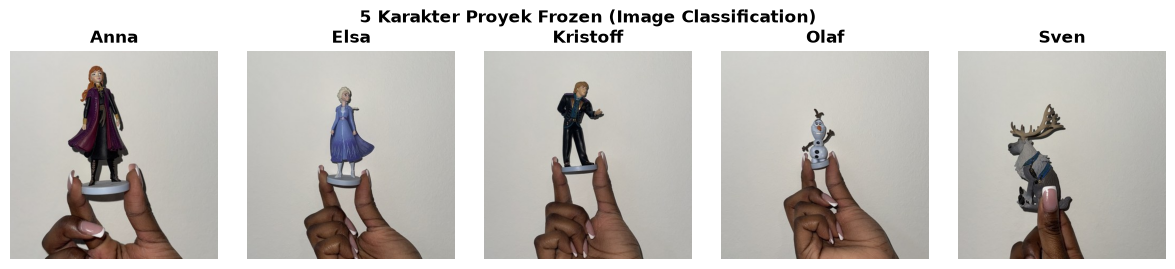

In [5]:
# Baca tabel metadata foto Frozen secara dinamis & urutkan berdasarkan nama file
df_meta = pd.read_csv(DATA_DIR / "metadata.csv").sort_values("file").reset_index(drop=True)
print("Total foto tersedia :", len(df_meta))
print(pd.crosstab(df_meta["kelas"], df_meta["kondisi"], margins=True))

# Tampilkan 5 contoh karakter Frozen
tampilkan_galeri_frozen(df_meta, DATA_DIR)

---
## Tahap 1 (9 menit): Foto Menjadi Kotak Piksel & Angka RGB *(Sesuai Slide 20 & 44)*

### Tahap 1.1: Kecilkan Foto Elsa ke Grid `8×8` & Normalisasi ke `0.0–1.0`
Pertama, kita buka **1 foto asli Elsa** dan mengecilkannya ke `8×8` kotak agar kita bisa melihat **angka di dalam setiap piksel** dengan mata telanjang!

### Tugas 1.1 (`# TODO 1`): Normalisasi Piksel Foto Elsa dari `0–255` ke `0.0–1.0`
Bagi `arr_8x8` dengan `255.0` agar semua nilai piksel berada di rentang `0.0` sampai `1.0`, lalu lihat hasilnya langsung sebagai gambar grid angka!

Shape foto_mini : (8, 8, 3) | Rentang nilai: 0.31 s/d 0.81


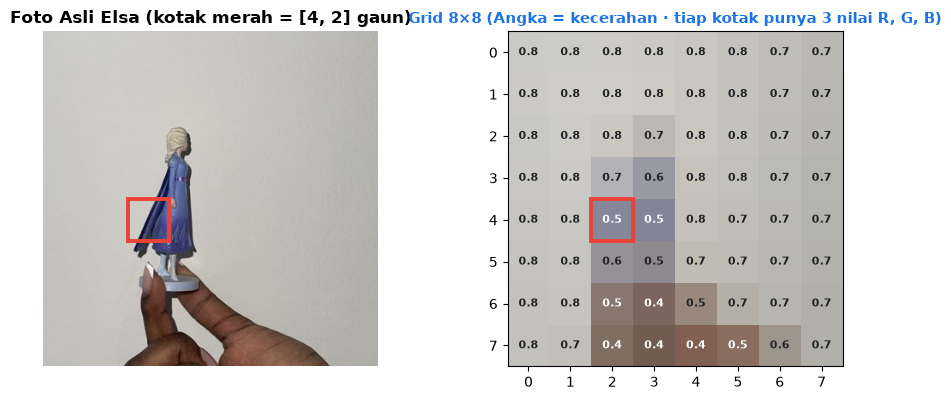

✅ Tahap 1.1 selesai!


In [6]:
# Buka 1 foto polos Elsa & kecilkan ke 8x8 kotak piksel
baris_elsa = df_meta[(df_meta["kelas"] == "elsa") & (df_meta["kondisi"] == "polos")].iloc[1]
foto_elsa = _crop_figur(_buka_foto_aman(DATA_DIR / baris_elsa["file"]))
arr_8x8 = np.array(foto_elsa.resize((8, 8), Image.Resampling.BILINEAR), dtype=np.float32)

# Ubah rentang angka piksel 0-255 menjadi 0.0-1.0
foto_mini = arr_8x8 / 255.0

assert foto_mini is not None, "Hapus None dan isi dengan arr_8x8 / 255.0"
assert foto_mini.shape == (8, 8, 3), f"Shape harus (8, 8, 3), didapat {foto_mini.shape}"
assert foto_mini.max() <= 1.0, "Nilai masih > 1.0! Pastikan arr_8x8 sudah dibagi 255.0"
print("Shape foto_mini :", foto_mini.shape, "| Rentang nilai:", round(float(foto_mini.min()), 2), "s/d", round(float(foto_mini.max()), 2))
tampilkan_piksel_grid(foto_elsa, foto_mini, pr=4, pc=2)
print("✅ Tahap 1.1 selesai!")

### Tugas 1.2 (`# TODO 2`): Intip 1 Piksel Gaun Biru Elsa `[4, 2]` (3 Angka RGB)
Ambil 1 kotak piksel di baris `4`, kolom `2` dari `foto_mini` (`foto_mini[4, 2]`). Perhatikan batang warna **Blue (B)** yang paling tinggi karena itu warna gaun biru Elsa!

Nilai [R, G, B] piksel [4, 2] : [0.52 0.53 0.6 ]


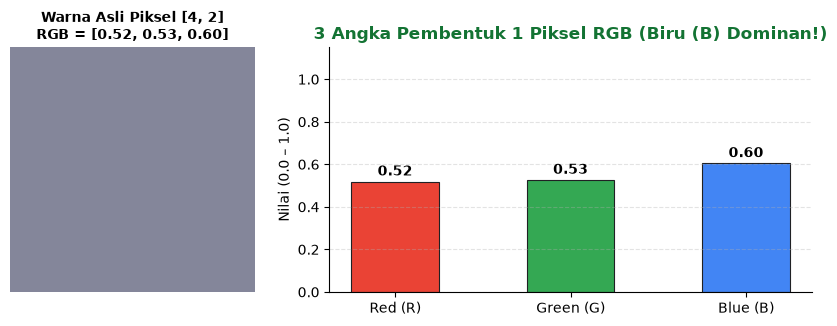

✅ Tahap 1.2 selesai!


In [7]:
# Ambil 1 piksel di baris 4, kolom 2 (tepat di gaun biru Elsa)
piksel_gaun = foto_mini[4, 2]

assert piksel_gaun is not None, "Isi piksel_gaun dengan foto_mini[4, 2]"
assert len(piksel_gaun) == 3, "1 piksel RGB harus memiliki tepat 3 angka [R, G, B]"
print("Nilai [R, G, B] piksel [4, 2] :", np.round(piksel_gaun, 2))
tampilkan_zoom_piksel(foto_mini, 4, 2, piksel_gaun)
print("✅ Tahap 1.2 selesai!")

> 💡 **Apa yang perlu diperhatikan di Tahap 1?**  
> Di grid `8×8`, angka yang tertulis di dalam kotak hanyalah *kecerahan rata-rata* agar mudah dibaca. Aslinya, **setiap 1 kotak piksel menyimpan 3 angka `[R, G, B]`** — terbukti pada piksel `[4, 2]` gaun Elsa yang nilai **Biru (B)**-nya paling tinggi!

---
## Tahap 2 (9 menit): *Flatten* Foto 2D Menjadi Pita 1D *(Sesuai Slide 21–24 & 45)*

### Tahap 2.1: Lihat Langsung Foto `8×8` Diluruskan Menjadi Pita 1D!
*Input Layer* Neural Network hanya menerima **1 deretan angka lurus (1D)**. Mari potong baris `B1` sampai `B8` dan jajarkan menjadi 1 pita warna panjang dengan `.flatten()`!

### Tugas 2.1 (`# TODO 3`): Luruskan `foto_mini` dengan `.flatten()` & Lihat Gambar Pitanya
Panggil `foto_mini.flatten()` lalu lihat langsung bagaimana kotak 2D `8×8` berubah menjadi 1 pita panjang berisi `64` piksel warna (`P1..P64`, masing-masing 3 angka RGB → total **`192` neuron input**)!

Sebelum Flatten (3D) : (8, 8, 3)
Sesudah Flatten (1D) : (192,) -> 64 piksel x 3 RGB = 192 neuron input!


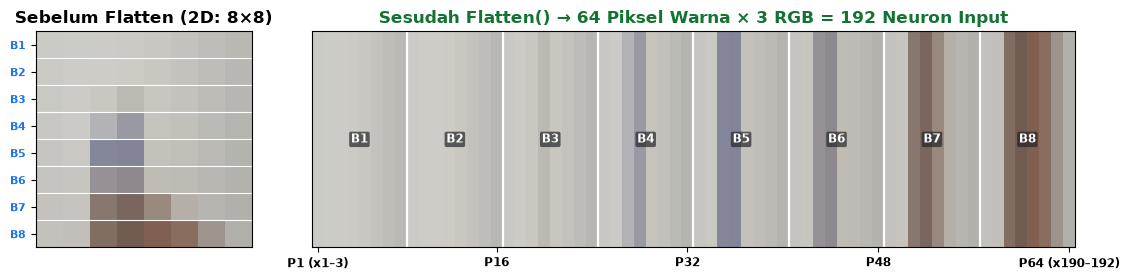

✅ Tahap 2.1 selesai!


In [8]:
# Luruskan foto_mini (8, 8, 3) menjadi 1 vektor lurus memakai .flatten()
vektor_elsa = foto_mini.flatten()

assert vektor_elsa is not None, "Isi vektor_elsa dengan foto_mini.flatten()"
assert vektor_elsa.ndim == 1 and len(vektor_elsa) == 8 * 8 * 3, "Panjang vektor 8x8x3 harus tepat 192 angka"
print("Sebelum Flatten (3D) :", foto_mini.shape)
print("Sesudah Flatten (1D) :", vektor_elsa.shape, "-> 64 piksel x 3 RGB = 192 neuron input!")
tampilkan_visual_flatten(foto_mini, vektor_elsa)
print("✅ Tahap 2.1 selesai!")

### Tugas 2.2 (`# TODO 4`): Hitung Skala Foto Penuh `224×224×3` (`752.645` Parameter)
Jika foto berukuran penuh `224×224×3` (seperti Slide 24 & 33), hitung `neuron_224 = IMG_SIZE * IMG_SIZE * 3` dan `param_224 = neuron_224 * len(CLASS_NAMES) + len(CLASS_NAMES)`, lalu lihat grafik perbandingannya!

Foto 224x224x3 -> 150,528 neuron input -> 752,645 parameter (persis Slide 24 & 33!)


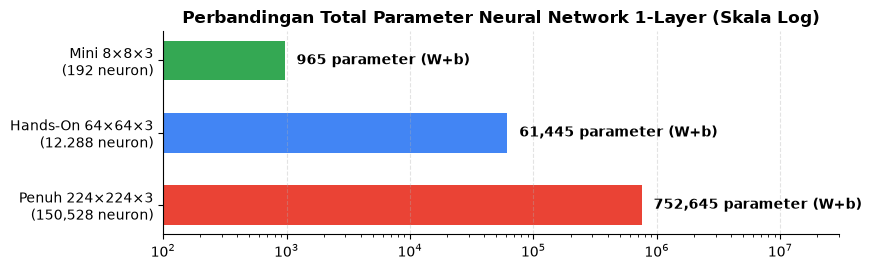

✅ Tahap 2.2 selesai!


In [9]:
# Hitung jumlah neuron input (H * W * C) dan total parameter (Input * 5 + 5)
neuron_224 = IMG_SIZE * IMG_SIZE * 3
param_224 = neuron_224 * len(CLASS_NAMES) + len(CLASS_NAMES)

assert neuron_224 == 150_528, f"Harusnya 224*224*3 = 150.528, didapat {neuron_224}"
assert param_224 == 752_645, f"Harusnya 150.528*5 + 5 = 752.645, didapat {param_224}"
print(f"Foto 224x224x3 -> {neuron_224:,} neuron input -> {param_224:,} parameter (persis Slide 24 & 33!)")
tampilkan_skala_parameter(neuron_224, param_224)
print("✅ Tahap 2.2 selesai!")

> 💡 **Apa yang perlu diperhatikan di Tahap 2?**  
> Lihat pita warna 1D di atas: garis biru gaun Elsa yang tadinya berada di tengah kotak 2D (baris `B4–B5`) sekarang terbentang lurus di tengah pita `P1..P64` (`x1..x192`). Semakin besar resolusi foto, jumlah kabel `W + b` melonjak cepat (`965 → 61.445 → 752.645`)!

---
## Tahap 3 (9 menit): Weight, Bias, `ReLU`, `Softmax` & `Loss` *(Sesuai Slide 27–29 & 46)*

### Tahap 3.1: Hitung 1 Neuron Pakai Kali-Tambah Biasa *(Gaun Biru vs Dinding!)*
Kita pakai **piksel gaun biru Elsa (`[r, g, b]`)** dari Tahap 1.2!  
Bayangkan neuron pendeteksi warna biru memberi bobot besar pada Biru (`w_b = +5.0`) dan bobot negatif pada Merah & Hijau (`w_r = -3.0, w_g = -2.0`), lalu kita bandingkan skornya dengan **piksel dinding polos `[0, 0]`**!

### Tugas 3.1 (`# TODO 5`): Hitung Skor `z = (r * w_r) + (g * w_g) + (b * w_b) + bias`
Kalikan tiap nilai piksel (`r, g, b`) dengan bobotnya (`w_r, w_g, w_b`), jumlahkan semua, lalu tambah `bias` — persis hitungan matematika sederhana!

Skor z (Piksel Gaun Biru) = +0.37


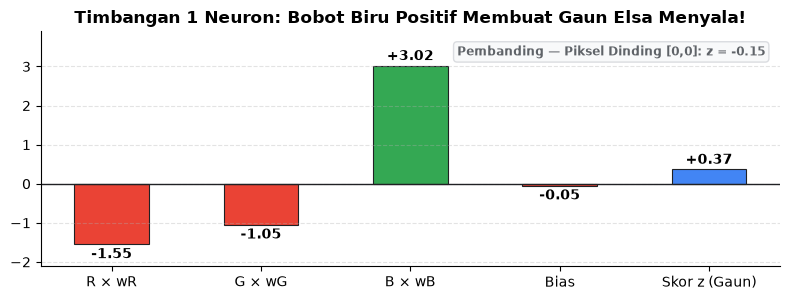

✅ Tahap 3.1 selesai!


In [10]:
# Ambil nilai r, g, b dari piksel gaun Elsa di Tahap 1.2
r, g, b = float(piksel_gaun[0]), float(piksel_gaun[1]), float(piksel_gaun[2])
w_r, w_g, w_b, bias = -3.0, -2.0, 5.0, -0.05

# Hitung total skor neuron: setiap input dikali bobot lalu ditambah bias
z = (r * w_r) + (g * w_g) + (b * w_b) + bias

assert z is not None, "Hapus None dan tulis rumus (r * w_r) + (g * w_g) + (b * w_b) + bias"
assert np.isclose(z, (r * w_r) + (g * w_g) + (b * w_b) + bias), "Cek lagi tanda kali (*) dan tambah (+) pada rumus z!"
print(f"Skor z (Piksel Gaun Biru) = {z:+.2f}")
tampilkan_timbangan_neuron(r, g, b, w_r, w_g, w_b, bias, z, piksel_dinding=foto_mini[0, 0])
print("✅ Tahap 3.1 selesai!")

### Tugas 3.2 (`# TODO 6`): Coba Fungsi Aktivasi `ReLU` (& Bandingkan dengan `Tanh` Slide 28)
Gunakan `np.maximum(0.0, skor_contoh)` untuk mengubah semua angka negatif menjadi `0` sambil membiarkan angka positif tetap menyala, lalu bandingkan sekilas dengan `np.tanh(...)` (`−1 s/d +1`).

Sebelum ReLU : [-1.2 -0.4  0.   0.8  2.1]
Sesudah ReLU : [0.  0.  0.  0.8 2.1] (negatif -> 0)
Banding Tanh : [-0.83 -0.38  0.    0.66  0.97] (Slide 28: terpusat -1..+1)


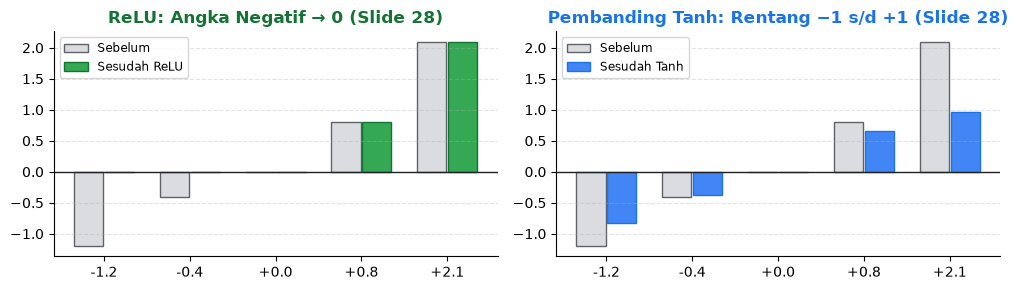

✅ Tahap 3.2 selesai!


In [11]:
skor_contoh = np.array([-1.2, -0.4, 0.0, 0.8, 2.1])

# Terapkan ReLU: angka negatif menjadi 0, angka positif tetap
hasil_relu = np.maximum(0.0, skor_contoh)

assert hasil_relu is not None, "Isi hasil_relu dengan np.maximum(0.0, skor_contoh)"
assert hasil_relu[0] == 0.0 and np.isclose(hasil_relu[-1], 2.1), "Pastikan negatif jadi 0.0 dan 2.1 tetap 2.1!"
print("Sebelum ReLU :", skor_contoh)
print("Sesudah ReLU :", hasil_relu, "(negatif -> 0)")
print("Banding Tanh :", np.round(np.tanh(skor_contoh), 2), "(Slide 28: terpusat -1..+1)")
tampilkan_relu(skor_contoh, hasil_relu)
print("✅ Tahap 3.2 selesai!")

### Tahap 3.3: Eksperimen Santai `Softmax`, `Argmax`, & `Cross-Entropy Loss (−ln P)` *(Ubah 1 Angka!)*
Di bawah ini ada 5 skor mentah untuk foto **Elsa**.  
1. Jalankan dulu → lihat probabilitas Elsa **`68.3%`** dan **`Loss = 0.38`** *(kecil ✓)*.  
2. Sekarang **coba ubah `skor_olaf = 3.0`** lalu tekan `Shift+Enter` → lihat pemenang `Argmax` berpindah ke **Olaf (salah!)** dan nilai **`Loss`** langsung melonjak merah!

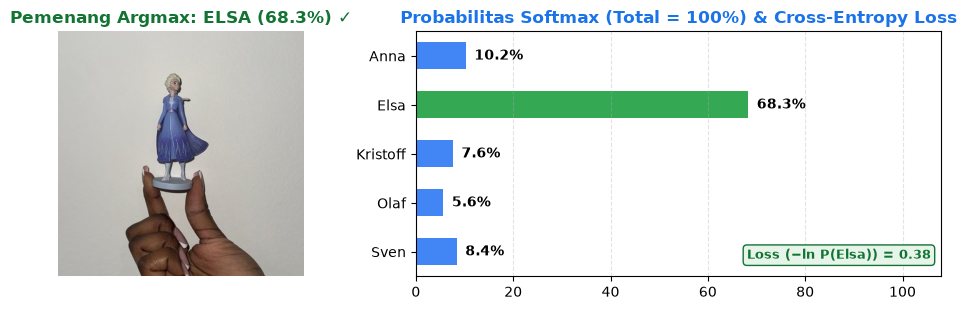

In [12]:
# Ubah salah satu angka skor mentah di bawah (mis. skor_olaf = 3.0), lalu tekan Shift+Enter!
skor_anna     = 0.4
skor_elsa     = 2.3
skor_kristoff = 0.1
skor_olaf     = -0.2
skor_sven     = 0.2

tampilkan_softmax_frozen([skor_anna, skor_elsa, skor_kristoff, skor_olaf, skor_sven], df_meta, DATA_DIR, label_asli="elsa")

> 💡 **Apa yang perlu diperhatikan di Tahap 3?**  
> `Weight + Bias` (kali-tambah) menghitung skor mentah `z`; `ReLU`/`Tanh`/`Sigmoid` membentuk sifat aktivasi non-linear (**Slide 28**); lalu di ujung model Multi-Class, `Softmax` mengubah 5 skor mentah menjadi probabilitas `100%` dan `Cross-Entropy Loss (−ln P)` menghukum tebakan yang salah (**Slide 29**)!

---
## Tahap 4 (9,5 menit): Bangun Neural Network 1-Layer & Uji "Model Bayi" *(Sesuai Slide 24, 31 & 47)*

### Tahap 4.1: Muat Seluruh Foto Frozen Ukuran `64×64` *(Cukup `Shift + Enter`)*
Kita pakai ukuran ringkas `64×64×3` (`12.288` piksel) agar training selesai dalam hitungan **2 detik** di laptop atau Google Colab! Sekaligus kita siapkan 5 contoh foto `polos` (`X_5foto`) dan 5 contoh foto `ramai` (`X_5ramai`)!

In [13]:
# Muat seluruh foto Frozen ke ukuran 64x64 (skala 0.0-1.0) secara dinamis
SMALL_SIZE = 64
X_frozen, y_frozen, kondisi_frozen, (X_5foto, y_5foto), (X_5ramai, y_5ramai) = muat_dataset_frozen(
    df_meta, DATA_DIR, small_size=SMALL_SIZE
)
n_polos = int((kondisi_frozen == "polos").sum())
n_ramai = int((kondisi_frozen == "ramai").sum())
print(f"Siap dilatih! Total: {len(X_frozen)} foto ({n_polos} polos, {n_ramai} ramai) | Shape: {X_frozen.shape}")

Siap dilatih! Total: 143 foto (102 polos, 41 ramai) | Shape: (143, 64, 64, 3)


### Tugas 4.2 (`# TODO 7`): Rakit 2 Layer Neural Network di Keras & Cocokkan `61.445` Parameter
Isi 2 bagian di dalam `tf.keras.Sequential([...])`: `tf.keras.layers.Flatten()` untuk meluruskan foto, dan `tf.keras.layers.Dense(len(CLASS_NAMES), activation='softmax')` untuk 5 neuron output!

In [14]:
tf.keras.utils.set_random_seed(SEED)

# Susun Neural Network 1-Layer persis diagram Slide 24 & 33: Input -> Flatten -> Dense(5, softmax)
model_nn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SMALL_SIZE, SMALL_SIZE, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
])

model_nn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
expected_p = (SMALL_SIZE * SMALL_SIZE * 3 * len(CLASS_NAMES)) + len(CLASS_NAMES)
assert model_nn.count_params() == expected_p, f"Parameter harus {expected_p:,}, didapat {model_nn.count_params():,}"
model_nn.summary()
print(f"✅ Tahap 4.2 selesai! Cocok 100% dengan rumus = {expected_p:,} parameter!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        61,445 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,445 (240.02 KB)

 Trainable params: 61,445 (240.02 KB)

 Non-trainable params: 0 (0.00 B)

✅ Tahap 4.2 selesai! Cocok 100% dengan rumus = 61,445 parameter!


### Tahap 4.3: Uji Tebakan **"Model Bayi" (Epoch 0 — *Weight Initialization* Acak, Slide 31!)**
Sebelum kita latih, mari simpan salinan bobot acak awalnya (`W_awal` dari *Weight Initialization*) dan suruh model menebak 5 foto Frozen!  
Perhatikan garis putus-putus `20%`: karena bobotnya masih acak (belum mengalami *Gradient Descent*), tebakan model hampir rata semua seperti melempar dadu!

Sebelum Belajar (Epoch 0) -> Loss = 1.71 | Akurasi = 24.5%


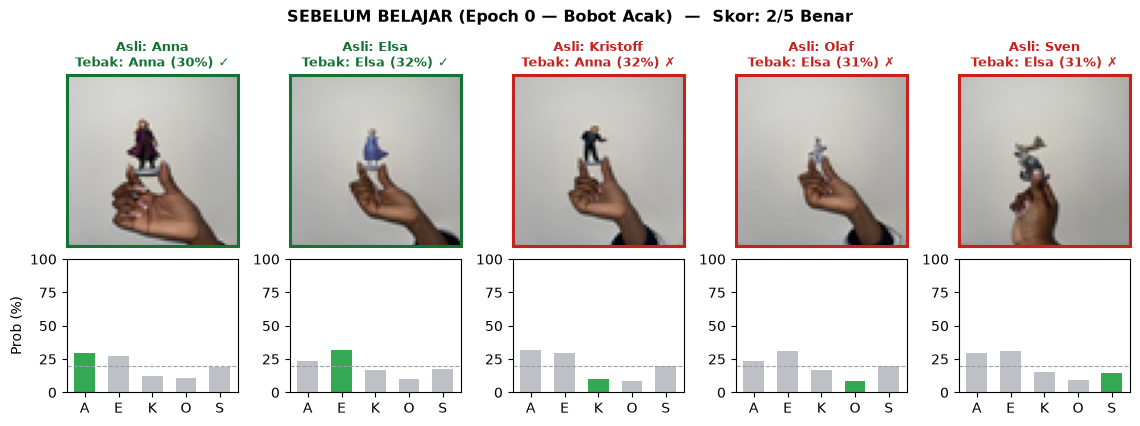

In [15]:
# Simpan salinan bobot acak awal (nanti dipakai di Tahap 5.4 untuk mengintip perubahan bobot!)
W_awal = model_nn.layers[-1].get_weights()[0].copy()

loss_e0, acc_e0 = model_nn.evaluate(X_frozen, y_frozen, verbose=0)
print(f"Sebelum Belajar (Epoch 0) -> Loss = {loss_e0:.2f} | Akurasi = {acc_e0*100:.1f}%")
tampilkan_tebakan_model(model_nn, X_5foto, y_5foto, judul="SEBELUM BELAJAR (Epoch 0 — Bobot Acak)")

---
## Tahap 5 (18 menit): Latih Model (`model.fit`), Before vs After & Intip Bobot! *(Sesuai Slide 30–33 & 48–49)*

### Tahap 5.1: Jalankan Proses Belajar (`model_nn.fit`)
Di satu baris perintah `model_nn.fit(..., epochs=EPOCHS, batch_size=16)` ini, Keras menjalankan seluruh siklus **Bab 3**: membagi foto menjadi paket **16 foto (`Batch Size`) → `Step`** (persis **Slide 32**!), lalu mengulang **Forward Pass → Loss → Backprop → Adam Optimizer** selama `EPOCHS`!  
*(Catatan metodologi: di sesi konsep ini seluruh foto dipakai untuk demo belajar; pembagian `train/val/test` resmi anti-leakage akan kita pelajari tuntas di **P05**.)*

### Tugas 5.1 (`# TODO 8`): Latih Model dengan `model_nn.fit(...)`
Panggil `model_nn.fit(X_frozen, y_frozen, epochs=EPOCHS, batch_size=16, verbose=1)` dan perhatikan angka step (`.../9` saat 143 foto), `loss` turun (`< 1.0`), serta `accuracy` naik!

In [16]:
EPOCHS = 2 if SMOKE_TEST else 30
steps_per_ep = int(np.ceil(len(X_frozen) / 16))
print(f"Total foto: {len(X_frozen)} | batch_size=16 -> {steps_per_ep} Step per Epoch (persis Slide 32!)")

# Jalankan siklus belajar Forward Pass -> Loss -> Backprop -> Gradient Descent (Adam)
history = model_nn.fit(X_frozen, y_frozen, epochs=EPOCHS, batch_size=16, verbose=1)

assert history is not None and "loss" in history.history, "Panggil model_nn.fit(X_frozen, y_frozen, epochs=EPOCHS, batch_size=16, verbose=1)"
print(f"\nLoss Epoch 1     : {history.history['loss'][0]:.2f}")
print(f"Loss Epoch akhir : {history.history['loss'][-1]:.2f}  (turun!)")
print("✅ Tahap 5.1 selesai!")

Total foto: 143 | batch_size=16 -> 9 Step per Epoch (persis Slide 32!)
Epoch 1/30


1/9 ━━━━━━━━━━━━━━━━━━━━ 3s 390ms/step - accuracy: 0.1875 - loss: 1.7774

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1678 - loss: 3.0320  


Epoch 2/30


1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2500 - loss: 2.0223

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1538 - loss: 2.3315 


... (81 outputs left out)

Epoch 30/30


1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 1.0000 - loss: 0.6775

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7692 - loss: 0.8889 



Loss Epoch 1     : 3.03
Loss Epoch akhir : 0.89  (turun!)
✅ Tahap 5.1 selesai!


### Tahap 5.2: Plot Grafik Penurunan *Loss* & Kenaikan *Akurasi*

Grafik disimpan ke: D:\Haerul\HaloTech-Private-DeepLearning\results\p02_nn_loss_curve.png


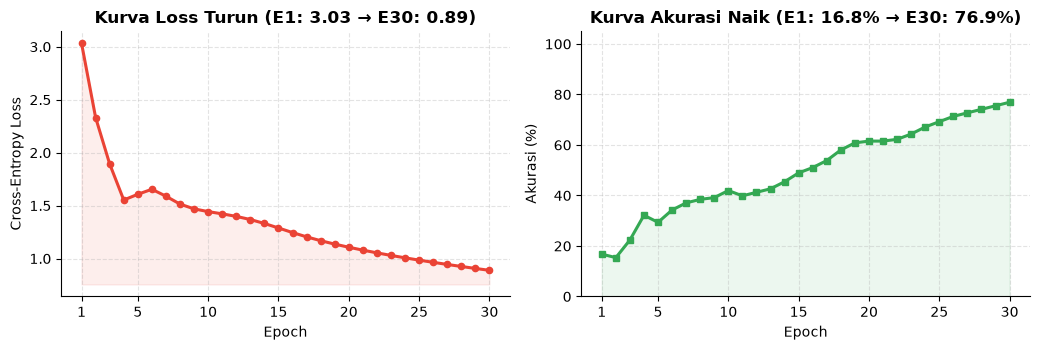

In [17]:
# Tampilkan grafik Loss & Akurasi, lalu simpan ke folder results/
loss_plot_path = RESULTS_DIR / "p02_nn_loss_curve.png"
tampilkan_kurva_training(history, simpan_ke=loss_plot_path)
assert loss_plot_path.exists()

### Tahap 5.3: Momen "Aha!" — Bandingkan **Before vs After** + Tes Foto **Polos vs Ramai**! *(Sesuai Slide 49)*
Lihat bagaimana bar probabilitas yang tadinya rata (~20% di Tahap 4.3) sekarang menebak tepat **5/5 karakter**!  
Lalu mari uji juga pada 5 foto berlatar **`ramai`** (`X_5ramai`).

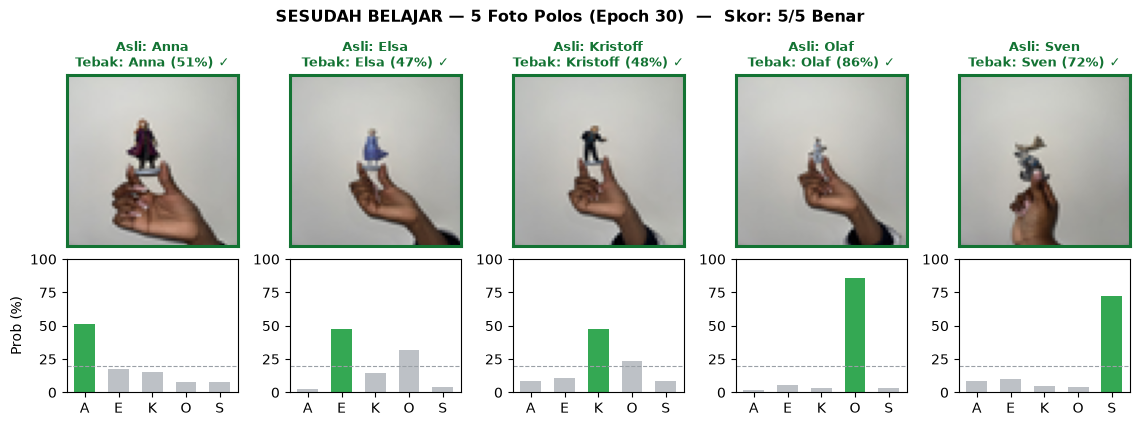

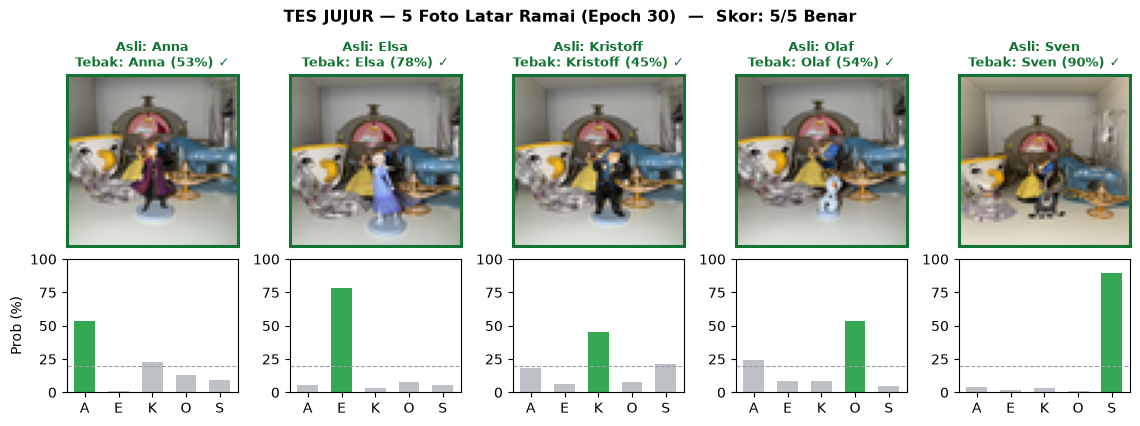

In [18]:
# Uji kembali 5 foto polos (Before vs After) lalu uji 5 foto berlatar RAMAI!
tampilkan_tebakan_model(model_nn, X_5foto, y_5foto, judul=f"SESUDAH BELAJAR — 5 Foto Polos (Epoch {EPOCHS})")
tampilkan_tebakan_model(model_nn, X_5ramai, y_5ramai, judul=f"TES JUJUR — 5 Foto Latar Ramai (Epoch {EPOCHS})")

### Cek Akurasi `Polos` vs `Ramai` pada Data Latih *(Indikasi Shortcut Learning · Slide 32 & 49)*
Mengapa skor foto `ramai` tampak tinggi saat diuji pada data latih? Karena jaringan 1-layer menghafal warna latar rak (*overfitting / shortcut*) — pembagian data **Group Split (P05)** & arsitektur **CNN (P03)** akan menyelesaikan ini!

In [19]:
# Hitung & bandingkan akurasi keseluruhan foto polos vs ramai
_, acc_polos = model_nn.evaluate(X_frozen[kondisi_frozen == "polos"], y_frozen[kondisi_frozen == "polos"], verbose=0)
_, acc_ramai = model_nn.evaluate(X_frozen[kondisi_frozen == "ramai"], y_frozen[kondisi_frozen == "ramai"], verbose=0)
print(f"Akurasi di data latih -> Polos = {acc_polos*100:.1f}% | Ramai = {acc_ramai*100:.1f}%")
assert 0.0 <= acc_polos <= 1.0 and 0.0 <= acc_ramai <= 1.0

Akurasi di data latih -> Polos = 77.5% | Ramai = 95.1%


### Tahap 5.4 *(Bonus Visual)*: Mengintip Isi Otak Bobot `ΔW` Overlay di Atas Foto *(Sesuai Slide 49!)*
Karena model kita hanya 1-Layer (`64×64×3 → 5`), kita dapat memvisualisasikan perubahan bobot (`W_akhir - W_awal`) langsung **di atas foto grayscale asli**!  
**Area terang menyala** menandai bagian figurin, jari pemegang, dan jejak latar belakang yang paling diingat neuron — alasan kuat kenapa kita beralih ke **CNN di P03**!

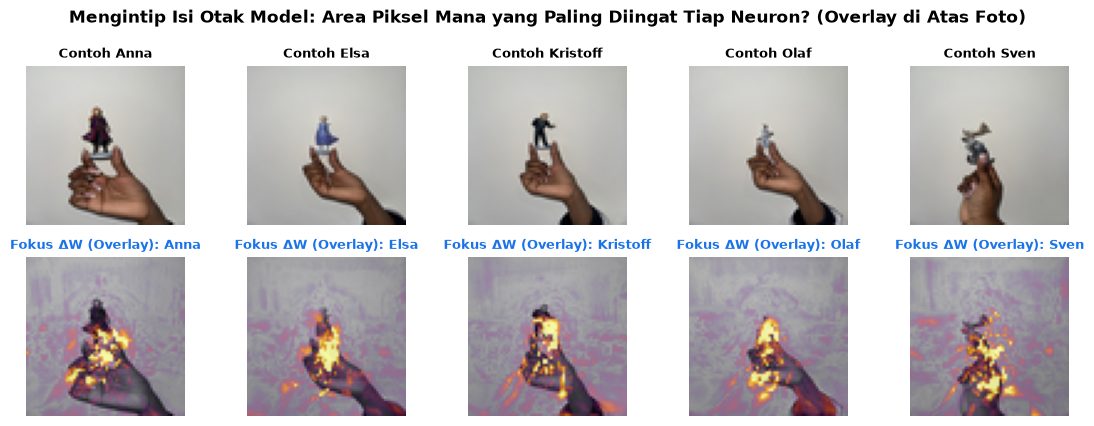

In [20]:
# Visualisasikan overlay peta perubahan bobot (W_akhir - W_awal) di atas foto Frozen
tampilkan_peta_bobot(model_nn, W_awal, X_5foto)

---
### Bonus Eksperimen Bebas *(Opsional)*: Ubah 1 Angka `LEARNING_RATE_COBA` *(Persis Slide 31!)*
Coba ganti `LEARNING_RATE_COBA` ke **`0.01`** *(langkah kebesaran / kurva memantul)* atau **`0.00005`** *(langkah kekecilan / sangat lambat)* lalu tekan `Shift+Enter` untuk membandingkan kurva Loss terhadap `LR Standar (0.0005)`!

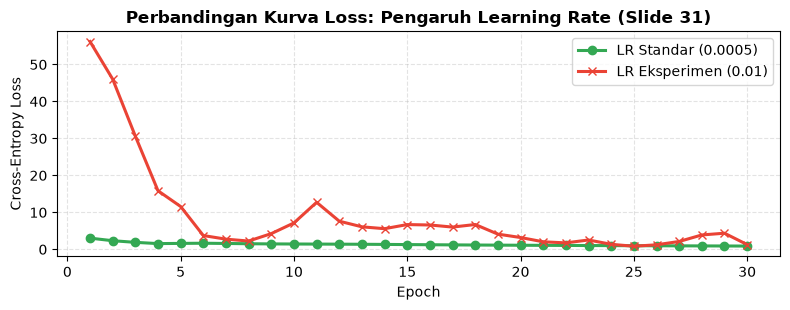

✅ Seluruh Hands-on P02 selesai! Siap lanjut ke Arsitektur Neural Network di P03!


In [21]:
# Ubah 1 angka ini (mis. 0.01 atau 0.00005) lalu tekan Shift+Enter!
LEARNING_RATE_COBA = 0.01
tampilkan_eksperimen_lr(X_frozen, y_frozen, history, lr_baru=LEARNING_RATE_COBA, epochs=EPOCHS, seed=SEED)
print("✅ Seluruh Hands-on P02 selesai! Siap lanjut ke Arsitektur Neural Network di P03!")

---
## Ringkasan Penutup Hands-On *(Selaras Slide 50–51)*
- **Piksel → Flatten → Dense(5) → Softmax → Backprop:** Seluruh rangkaian teori **Bab 3** sudah terbukti berjalan nyata pada dataset **Disney Frozen Figurine**!
- **Hasil Penting Hari Ini:** Model 1-Layer belajar dari tebak acak (`Epoch 0`) hingga melesat menebak benar dan menyimpan grafik kurva di `results/p02_nn_loss_curve.png`.
- **Siap ke P03:** Dari overlay `ΔW` kita melihat model 1-layer masih mengandalkan posisi & latar — di **P03 — Arsitektur Neural Network** kita melangkah ke arsitektur jaringan yang lebih tepat!

## Referensi Materi (Selaras Slide 41–42 · Bab 1, Bab 2 & Bab 3)

### Bagian 1 — Bab 1 (AI/ML/DL) & Bab 2 (Computer Vision)
1. [Google Machine Learning Crash Course](https://developers.google.com/machine-learning/crash-course) `[CEK LINK]` — *Bab 1: AI Klasik vs Modern & Supervised Learning (Slide 6–7)*
2. [Coursera — Deep Learning Specialization Course 1](https://www.coursera.org/specializations/deep-learning) `[CEK LINK]` — *Bab 1: ML vs DL & Feature Learning (Slide 7–9)*
3. [StatQuest — Machine Learning & Neural Networks](https://www.youtube.com/@statquest) `[CEK LINK]` — *Bab 1 & Bab 3: Intuisi Visual ML & Bobot/Aktivasi (Slide 7–9, 27–28)*
4. [Coursera (DeepLearning.AI) — Computer Vision Week 1](https://www.coursera.org/learn/convolutional-neural-networks) — *Bab 2: 4 Tugas Computer Vision (Slide 12–16)*
5. [Stanford CS231n — Image Classification Notes](https://cs231n.github.io/classification/) `[CEK LINK]` — *Bab 2: Binary vs Multi-Class Classification (Slide 13)*
6. [Dokumentasi Pillow (PIL) — Pengolahan Foto & Piksel](https://pillow.readthedocs.io/) `[CEK LINK]` — *Recap P01 & Hands-On Tahap 1 (Slide 3, 44)*

### Bagian 2 — Bab 3 (Teori Neural Network & Praktik Keras)
7. [3Blue1Brown — *But what is a Neural Network?*](https://www.youtube.com/watch?v=aircAruvnKk) *(Wajib)* — *Bab 3 Tahap 1–4: Piksel → Flatten → Weight/Bias → Softmax (Slide 20–29)*
8. [3Blue1Brown — *Playlist Neural Networks (Bab 1–4)*](https://www.youtube.com/playlist?list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi) — *Bab 3 Tahap 5: Loss, Gradient Descent & Backpropagation (Slide 30–33)*
9. [3Blue1Brown — *Versi Tulis Neural Networks*](https://3blue1brown.com/lessons/neural-networks) — *Bab 3: Bacaan Santai Forward Pass & Training (Slide 26–30)*
10. [TensorFlow Playground](https://playground.tensorflow.org/) `[CEK LINK]` — *Bab 3: Aktivasi (ReLU, Sigmoid, Tanh), LR & Overfitting (Slide 28, 31–32)*
11. [Keras Official — *The Sequential Model Guide*](https://keras.io/guides/sequential_model/) `[CEK LINK]` — *Bab 3 Dense & Hands-On Tahap 4–5 (Slide 24, 47–49)*
12. [Kingma & Ba — *Adam Optimizer* (`arXiv 1412.6980`)](https://arxiv.org/abs/1412.6980) `[CEK LINK]` — *Bab 3 Optimizer Adam & Hands-On compile() (Slide 31, 47–48)*